In [2]:
import nltk
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import movie_reviews

nltk.download("movie_reviews")
nltk.download("stopwords")
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("wordnet")

docs = []
for label in movie_reviews.categories():
    for fid in movie_reviews.fileids(label):
        docs.append((movie_reviews.raw(fid), label))

df = pd.DataFrame(docs, columns=["review", "sentiment"])
print(df.shape)
print(df["sentiment"].value_counts())
df.head()

[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


(2000, 2)
sentiment
neg    1000
pos    1000
Name: count, dtype: int64


,review,sentiment
0,"plot : two teen couples go to a church party ,...",neg
1,the happy bastard's quick movie review \ndamn ...,neg
2,it is movies like these that make a jaded movi...,neg
3,""" quest for camelot "" is warner bros . ' firs...",neg
4,synopsis : a mentally unstable man undergoing ...,neg


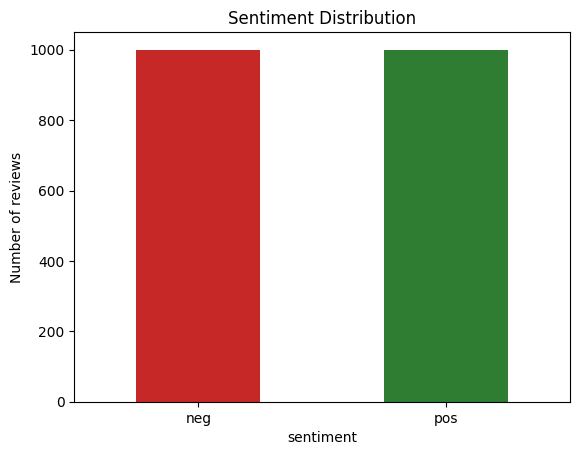

In [3]:
df["sentiment"].value_counts().plot(kind="bar", color=["#C62828", "#2E7D32"], title="Sentiment Distribution")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.show()

In [4]:
import re
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words and len(t) > 2]
    return " ".join(tokens)

df["clean_review"] = df["review"].apply(preprocess)
df[["review", "clean_review"]].head(3)

,review,clean_review
0,"plot : two teen couples go to a church party ,...",plot two teen couple church party drink drive ...
1,the happy bastard's quick movie review \ndamn ...,happy bastard quick movie review damn bug got ...
2,it is movies like these that make a jaded movi...,movie like make jaded movie viewer thankful in...


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["clean_review"], df["sentiment"], test_size=0.2, random_state=42, stratify=df["sentiment"]
)

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print(X_train_tfidf.shape, X_test_tfidf.shape)

(1600, 5000) (400, 5000)


Naive Bayes
              precision    recall  f1-score   support

         neg       0.81      0.83      0.82       200
         pos       0.83      0.81      0.82       200

    accuracy                           0.82       400
   macro avg       0.82      0.82      0.82       400
weighted avg       0.82      0.82      0.82       400



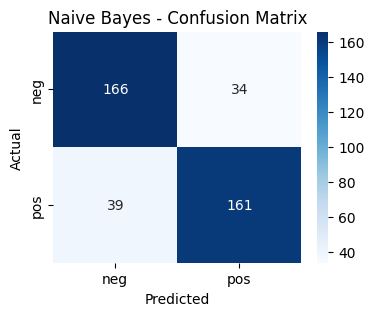

Logistic Regression
              precision    recall  f1-score   support

         neg       0.84      0.81      0.83       200
         pos       0.82      0.84      0.83       200

    accuracy                           0.83       400
   macro avg       0.83      0.83      0.83       400
weighted avg       0.83      0.83      0.83       400



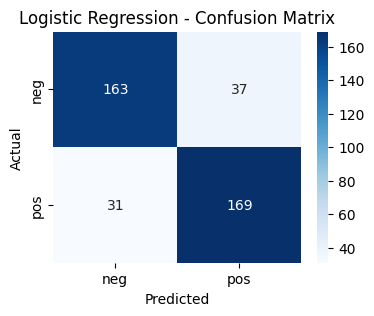

,Accuracy,Precision,Recall,F1
Naive Bayes,0.818,0.826,0.805,0.815
Logistic Regression,0.830,0.820,0.845,0.833


In [6]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
}

results = {}
predictions = {}
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    pred = model.predict(X_test_tfidf)
    predictions[name] = pred
    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, pos_label="pos"),
        "Recall": recall_score(y_test, pred, pos_label="pos"),
        "F1": f1_score(y_test, pred, pos_label="pos"),
    }

    print("=" * 50)
    print(name)
    print(classification_report(y_test, pred))

    cm = confusion_matrix(y_test, pred, labels=["neg", "pos"])
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

pd.DataFrame(results).T.round(3)

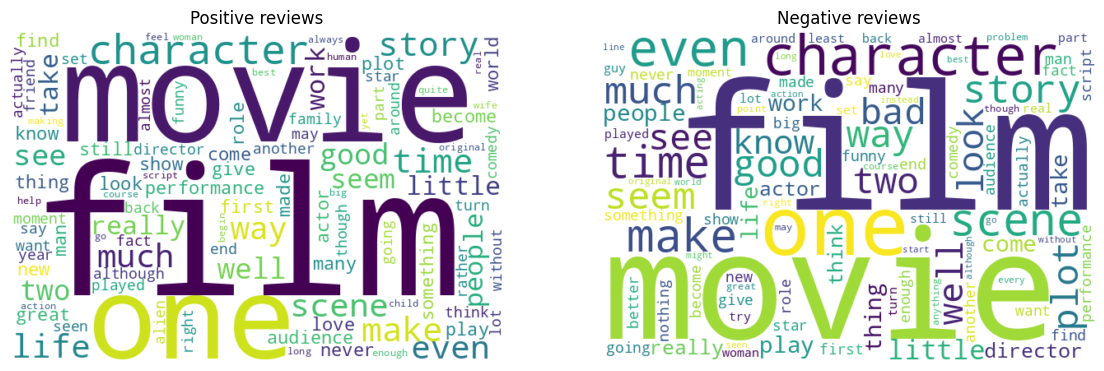

In [7]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, label in zip(axes, ["pos", "neg"]):
    text = " ".join(df[df["sentiment"] == label]["clean_review"])
    wc = WordCloud(width=600, height=400, background_color="white", max_words=100).generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title("Positive reviews" if label == "pos" else "Negative reviews")
    ax.axis("off")
plt.show()

In [8]:
best_name = max(results, key=lambda k: results[k]["Accuracy"])
pred = predictions[best_name]

errors = pd.DataFrame({
    "review": df.loc[X_test.index, "review"].values,
    "actual": y_test.values,
    "predicted": pred,
})
wrong = errors[errors["actual"] != errors["predicted"]].head(5)

print("Best model:", best_name)
for i, row in wrong.iterrows():
    print("-" * 60)
    print("Actual:", row["actual"], "| Predicted:", row["predicted"])
    print(row["review"][:300].replace("\n", " "), "...")

Best model: Logistic Regression
------------------------------------------------------------
Actual: neg | Predicted: pos
running time approximately 1hr 40mins  reviewed by jack choo  rating :  the movie starts with a rather se7en-ish opening sequence , rather cool and sets the mood for things to come .  the story propels the audience into a neo-reality ; somewhat very close to conscious reality but laced with weird ti ...
------------------------------------------------------------
Actual: neg | Predicted: pos
in the line of duty is the critically praised series of television movies dealing with the real-life incidents that claimed lives of law enforcement officers in usa .  the twilight murders , another one from the series , is dealing with the case of gordon kahl ( played by rod steiger ) , old farmer  ...
------------------------------------------------------------
Actual: neg | Predicted: pos
according to popular film opinion , a film's greatness is determined by time .  take for

In [ ]:
import os, json
os.chdir("/content")
from getpass import getpass
from google.colab import _message

token = getpass("Paste GitHub token: ").strip()
if not (token.startswith("ghp_") or token.startswith("github_pat_")) or len(token) > 120:
    raise SystemExit("This is not a GitHub token. Copy the token (starts with ghp_) and run the cell again.")

nb = _message.blocking_request('get_ipynb', timeout_sec=120)['ipynb']

!rm -rf /content/OIBSIP
!git clone https://{token}@github.com/Ali-Bin-Talib/OIBSIP.git /content/OIBSIP

folder = "/content/OIBSIP/DataAnalytics-L1-SentimentAnalysis"
os.makedirs(folder, exist_ok=True)

with open(folder + "/Sentiment_Analysis.ipynb", "w") as f:
    json.dump(nb, f)

readme = """# Sentiment Analysis on Movie Reviews

A machine learning project that classifies movie reviews as positive or negative using NLP.

## What this project does
- Loads 2000 movie reviews (NLTK movie_reviews) and checks the class distribution
- Text preprocessing: lowercase, punctuation removal, tokenisation, stopword removal, lemmatization
- TF-IDF feature extraction
- 80/20 train/test split
- Trains Naive Bayes and Logistic Regression
- Evaluates with accuracy, precision, recall, F1-score and confusion matrices
- Sentiment distribution bar chart and word clouds for each class
- Error analysis of misclassified reviews
- Conclusion on the best model and real-world use

## Dataset
NLTK movie_reviews corpus. It contains only positive and negative reviews, so this is a binary classification task.

## Tech Stack
Python, pandas, NLTK, scikit-learn, matplotlib, seaborn, WordCloud, Jupyter Notebook (Google Colab)

## How to Run
Open Sentiment_Analysis.ipynb in Google Colab and run all cells. The dataset is downloaded automatically with NLTK.
"""
with open(folder + "/README.md", "w") as f:
    f.write(readme)

os.chdir("/content/OIBSIP")
!git config user.email "alibintalib853@gmail.com"
!git config user.name "Ali Bin Talib"
!git add .
!git commit -m "Data Analytics L1: Sentiment Analysis"
!git push
os.chdir("/content")

Paste GitHub token: ··········
